# 03 — Data Preprocessing

## Objective
Prepare clean, verified target segmentation masks and standardized inputs for the Dual-Head Siamese training pipeline:
- Index and validate all `train` (2,799), `hold` (933), and `test` (933) tile pairs.
- Isolate `un-classified` building polygons with `IGNORE_INDEX = 255` so unlabelled rubble does not corrupt background gradients.
- Cache processed target masks once in `processed/targets/` while keeping original raw files untouched.
- Validate ImageNet RGB normalization for paired pre/post Siamese inputs.

## 1. Environment Setup & Split Completeness Audit
Initializes directory paths, random seeds, class mappings, and verifies 100% file completeness across `train`, `hold`, and `test`.

In [1]:
from pathlib import Path
from collections import Counter
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from PIL import Image
from rasterio.features import rasterize
from affine import Affine
from shapely import wkt
import torch

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASET_ROOT = PROJECT_ROOT / "dataset"
PROCESSED_ROOT = PROJECT_ROOT / "processed"
TARGET_CACHE_ROOT = PROCESSED_ROOT / "targets"
SPLITS = ["train", "hold", "test"]
IMAGE_SIZE = (1024, 1024)
IGNORE_INDEX = 255
CLASS_MAPPING = {0: "background", 1: "no-damage", 2: "minor-damage", 3: "major-damage", 4: "destroyed"}

def build_split_index(split):
    split_root = DATASET_ROOT / split
    pre_imgs = {p.stem.replace("_pre_disaster", ""): p for p in (split_root / "images").glob("*_pre_disaster.png")}
    post_imgs = {p.stem.replace("_post_disaster", ""): p for p in (split_root / "images").glob("*_post_disaster.png")}
    pre_masks = {p.stem.replace("_pre_disaster_target", ""): p for p in (split_root / "targets").glob("*_pre_disaster_target.png")}
    post_masks = {p.stem.replace("_post_disaster_target", ""): p for p in (split_root / "targets").glob("*_post_disaster_target.png")}
    pre_labels = {p.stem.replace("_pre_disaster", ""): p for p in (split_root / "labels").glob("*_pre_disaster.json")}
    post_labels = {p.stem.replace("_post_disaster", ""): p for p in (split_root / "labels").glob("*_post_disaster.json")}
    tile_ids = sorted(set(pre_imgs) & set(post_imgs) & set(pre_masks) & set(post_masks) & set(pre_labels) & set(post_labels))
    return pd.DataFrame([{
        "tile_id": tid,
        "pre_image": pre_imgs[tid],
        "post_image": post_imgs[tid],
        "pre_mask": pre_masks[tid],
        "post_mask": post_masks[tid],
        "pre_label": pre_labels[tid],
        "post_label": post_labels[tid]
    } for tid in tile_ids])

split_indexes = {s: build_split_index(s) for s in SPLITS}
for s, df in split_indexes.items():
    print(f"{s.upper():<6}: {len(df):,} complete tile pairs")

TRAIN : 2,799 complete tile pairs
HOLD  : 933 complete tile pairs
TEST  : 933 complete tile pairs


## 2. Annotation Subtype & Raw Mask Value Audit
Audits post-disaster JSON annotations across all splits to locate `un-classified` buildings and confirms raw PNG masks contain only integers `{0, 1, 2, 3, 4}`.

In [2]:
subtype_rows = []
for split, df in split_indexes.items():
    counts = Counter()
    tiles_with_unclassified = []
    for _, row in df.iterrows():
        with open(row["post_label"], "r") as f:
            buildings = json.load(f).get("features", {}).get("xy", [])
        tile_has_unc = False
        for b in buildings:
            st = b.get("properties", {}).get("subtype") or "missing"
            counts[st] += 1
            if st == "un-classified":
                tile_has_unc = True
        if tile_has_unc:
            tiles_with_unclassified.append(row["tile_id"])
    subtype_rows.append({"Split": split, "Tiles w/ Unclassified": len(tiles_with_unclassified), **dict(counts)})
    if split == "train":
        sample_unclassified_tile = tiles_with_unclassified[0]

display(pd.DataFrame(subtype_rows).fillna(0).astype({k: int for k in ["no-damage", "minor-damage", "major-damage", "destroyed", "un-classified"] if k in pd.DataFrame(subtype_rows).columns}))

raw_vals = set()
for row in split_indexes["train"].sample(n=100, random_state=42).itertuples():
    raw_vals.update(np.unique(np.array(Image.open(row.post_mask))).tolist())
assert raw_vals.issubset(set(CLASS_MAPPING.keys()))
print("Verified raw mask pixel domain:", sorted(raw_vals))

   Split  Tiles w/ Unclassified  ...  major-damage  un-classified
0  train                    683  ...         14161           2993
1   hold                    258  ...          4605           1255
2   test                    231  ...          3850           1012

[3 rows x 7 columns]
Verified raw mask pixel domain: [0, 1, 2, 3, 4]


## 3. Ignore-Index Mask Generation (`255`) & Visual Verification
Defines `generate_unclassified_mask` and `generate_target_mask` to rasterize `un-classified` polygons and stamp them as `IGNORE_INDEX = 255`, preserving background integrity.

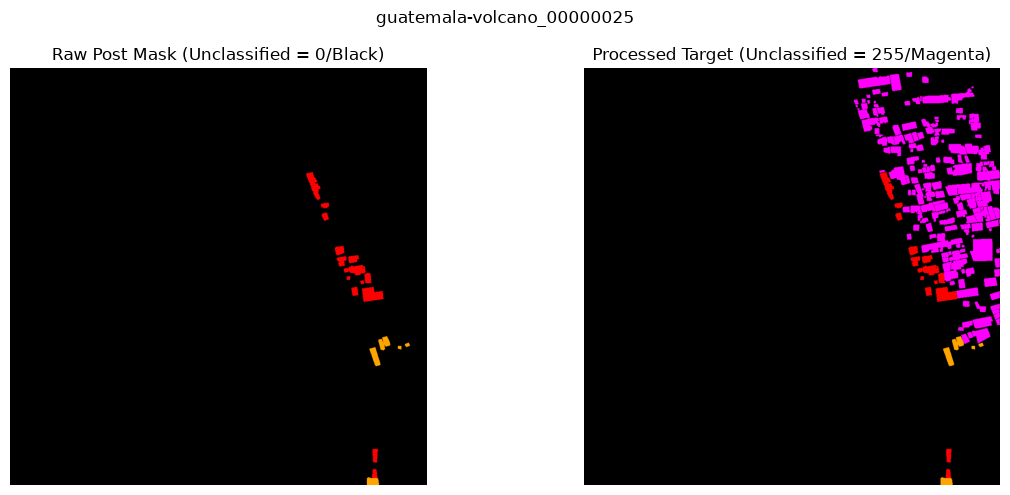

In [3]:
def generate_unclassified_mask(label_path):
    with open(label_path, "r") as f:
        data = json.load(f)
    geometries = []
    for feature in data.get("features", {}).get("xy", []):
        props = feature.get("properties", {})
        if props.get("feature_type") == "building" and props.get("subtype") == "un-classified":
            try:
                geom = wkt.loads(feature["wkt"])
                if not geom.is_empty and geom.is_valid:
                    geometries.append((geom, 1))
            except Exception:
                continue
    if not geometries:
        return np.zeros(IMAGE_SIZE, dtype=np.uint8)
    return rasterize(geometries, out_shape=IMAGE_SIZE, transform=Affine.identity(), fill=0, dtype=np.uint8, all_touched=False)

def generate_target_mask(post_mask_path, post_label_path):
    original_mask = np.array(Image.open(post_mask_path).convert("L"))
    assert original_mask.shape == IMAGE_SIZE
    ignore_mask = generate_unclassified_mask(post_label_path)
    target_mask = original_mask.copy()
    target_mask[ignore_mask == 1] = IGNORE_INDEX
    return target_mask

sample_row = split_indexes["train"].loc[split_indexes["train"]["tile_id"] == sample_unclassified_tile].iloc[0]
orig_mask = np.array(Image.open(sample_row["post_mask"]))
proc_mask = generate_target_mask(sample_row["post_mask"], sample_row["post_label"])
assert np.any(proc_mask == IGNORE_INDEX)

target_cmap = ListedColormap(["black", "green", "yellow", "orange", "red", "magenta"])
target_norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5, 4.5, 255.5], target_cmap.N)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(orig_mask, cmap=target_cmap, norm=target_norm)
axes[0].set_title("Raw Post Mask (Unclassified = 0/Black)")
axes[1].imshow(proc_mask, cmap=target_cmap, norm=target_norm)
axes[1].set_title("Processed Target (Unclassified = 255/Magenta)")
for ax in axes:
    ax.axis("off")
plt.suptitle(sample_unclassified_tile)
plt.tight_layout()
plt.show()

## 4. Processed Target Caching (`processed/targets/`)
Generates and caches processed target PNGs for `train`, `hold`, and `test`. Existing cached targets are skipped automatically for fast, idempotent re-execution.

In [4]:
for split in SPLITS:
    cache_dir = TARGET_CACHE_ROOT / split
    cache_dir.mkdir(parents=True, exist_ok=True)
    df = split_indexes[split]
    newly_created = 0
    for _, row in df.iterrows():
        cache_path = cache_dir / f"{row['tile_id']}.png"
        if cache_path.exists():
            continue
        target = generate_target_mask(row["post_mask"], row["post_label"])
        Image.fromarray(target.astype(np.uint8), mode="L").save(cache_path)
        newly_created += 1
    cached_files = list(cache_dir.glob("*.png"))
    assert len(cached_files) == len(df)
    sample = df.iloc[0]
    assert np.array_equal(np.array(Image.open(cache_dir / f"{sample['tile_id']}.png")), generate_target_mask(sample["post_mask"], sample["post_label"]))
    print(f"{split.upper():<6} | Total Cached: {len(cached_files):,} | Newly Generated: {newly_created} | Integrity: Verified")

TRAIN  | Total Cached: 2,799 | Newly Generated: 0 | Integrity: Verified
HOLD   | Total Cached: 933 | Newly Generated: 0 | Integrity: Verified
TEST   | Total Cached: 933 | Newly Generated: 0 | Integrity: Verified


## 5. Standardized Siamese Tensor Normalization Check
Verifies ImageNet mean/std normalization on paired `(3, 1024, 1024)` pre/post tensors alongside their cached target masks, matching the Dual-Head Siamese input specification.

In [5]:
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

sample = split_indexes["train"].iloc[0]
pre_arr = (np.array(Image.open(sample["pre_image"]).convert("RGB"), dtype=np.float32) / 255.0 - IMAGENET_MEAN) / IMAGENET_STD
post_arr = (np.array(Image.open(sample["post_image"]).convert("RGB"), dtype=np.float32) / 255.0 - IMAGENET_MEAN) / IMAGENET_STD
pre_t = torch.from_numpy(pre_arr.transpose(2, 0, 1))
post_t = torch.from_numpy(post_arr.transpose(2, 0, 1))
tgt_t = torch.from_numpy(np.array(Image.open(TARGET_CACHE_ROOT / "train" / f"{sample['tile_id']}.png"), dtype=np.int64))

assert pre_t.shape == (3, 1024, 1024) and post_t.shape == (3, 1024, 1024) and tgt_t.shape == (1024, 1024)
print(f"Verified Siamese Pair -> Pre: {tuple(pre_t.shape)} (mean={pre_t.mean():.3f}) | Post: {tuple(post_t.shape)} | Target classes: {torch.unique(tgt_t).tolist()}")

Verified Siamese Pair -> Pre: (3, 1024, 1024) (mean=-1.148) | Post: (3, 1024, 1024) | Target classes: [0, 1]


# 6. Preprocessing Summary & Conclusion

1. **Complete Split Indexing**: Verified 4,665 complete pre/post pairs (`2,799 train`, `933 hold`, `933 test`).
2. **Ignore Mask Isolation**: All `un-classified` buildings (`2,993` in train, `987` in hold, `1,158` in test) are cleanly rasterized into `IGNORE_INDEX = 255` and cached in `processed/targets/`.
3. **Input Standardization**: Pre- and post-disaster RGB images are converted to paired `(3, H, W)` tensors using ImageNet mean/std normalization, ready for guided 512×512 building cropping in Notebook 05.